# Praktikum 2 : Multinomial dan Gaussian Naive Bayes

Data dummy diganti rating dan review_count kafe

In [1]:
# Langkah 1 - Data PBL menggantikan data dummy
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder
data_kafe = pd.read_csv('../../dataset_pbl/cafes.csv')
X = data_kafe[['rating', 'review_count']].to_numpy()
le = LabelEncoder()
y = le.fit_transform(data_kafe['source_query'].fillna('Tidak tersedia'))
X = np.absolute(X)
X = (np.round(X, 2) * 100).astype(int)
print(X[:5])
print(y[:5])

[[   470  16700]
 [   450 157500]
 [   490  31600]
 [   459 177200]
 [   459  59600]]
[6 6 6 6 6]


In [2]:
# Langkah 2 (Opsional) - Membuat Data Frame

import pandas as pd

# Reshape label y menjadi 2D
# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
y_new = y.reshape(len(y), 1)

# Gabungkan fitur X dan label y dalam data array
data = np.concatenate((X, y_new), axis=1)

# Definisikan nama kolom
nama_kolom = ['rating', 'review_count', 'Label']

# Buat Data Frame
df = pd.DataFrame(data, columns=nama_kolom)

# Cek Data Frame
df.head()

,rating,review_count,Label
0,470,16700,6
1,450,157500,6
2,490,31600,6
3,459,177200,6
4,459,59600,6


In [3]:
# Langkah 3 - Labeling
labels = dict(enumerate(le.classes_))
df_label = df.copy()
df_label['Label'] = df_label['Label'].map(labels)
df_label.head()

,rating,review_count,Label
0,470,16700,Tidak tersedia
1,450,157500,Tidak tersedia
2,490,31600,Tidak tersedia
3,459,177200,Tidak tersedia
4,459,59600,Tidak tersedia


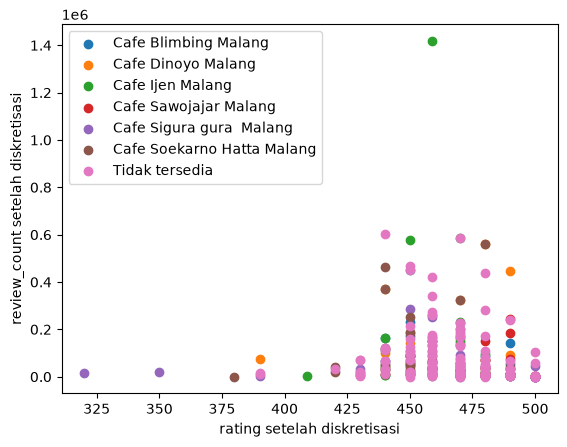

In [4]:
# Langkah 4 - Visualisasi
import matplotlib.pyplot as plt
for label, group in df_label.groupby('Label'):
    plt.scatter(group['rating'], group['review_count'], label=label)
plt.xlabel('rating setelah diskretisasi')
plt.ylabel('review_count setelah diskretisasi')
plt.legend()
plt.show()

In [5]:
# Langkah 5 - Model Multinomial Naive Bayes

from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi

# Inisiasi obyek MultinomialNB
mnb = MultinomialNB()

# Kita dapat langsung menggunakan fitur X dan label y
# hasil dari proses pembuatan data dummy

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

# Fit model
# Label y harus dalam bentuk 1D atau (n_samples,)
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred = mnb.predict(X_train)

# Evaluasi akurasi training
acc_train = accuracy_score(y_train, y_train_pred)

# Prediksi test data
y_test_pred = mnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test = accuracy_score(y_test, y_test_pred)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.18009478672985782
Hasil akurasi data test: 0.16483516483516483


In [6]:
# Langkah 6 - Model Gaussian Naive Bayes

from sklearn.naive_bayes import GaussianNB # class untuk model GaussianNB

# Inisiasi obyek Gaussian
gnb = GaussianNB()

# Kita menggunakan split data training dan testing
# yang sama dengan model multinomial

# Fit model
# Label y harus dalam bentu 1D atau (n_samples,)
gnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred_gnb = gnb.predict(X_train)

# Evaluasi akurasi training
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Prediksi test data
y_test_pred_gnb = gnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

# Print hasil evaluasi
print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.3981042654028436
Hasil akurasi data test (Gaussian): 0.4065934065934066
